<a href="https://colab.research.google.com/github/araujoluigif/cp5-statistical-computing/blob/main/CP6_SCWRP_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Checkpoint 6 — Statistical Computing with R & Python

Execute as células em ordem. Na célula **1. CARGA DA BASE**, selecione `CreditScoring.csv` quando o Colab solicitar. Os gráficos serão exibidos e salvos em `graficos/`.


In [16]:
# Checkpoint 6 - SCWRP

# Luigi Francisco RM:571204

# Breno Filipe RM:571824

# Igor Moreno RM:570353

# Diogo Lopes RM:570732


# =============================================================================
# Checkpoint 6 - Statistical Computing with R & Python (FIAP)
# Tema: Análise de crédito - valor do empréstimo e risco de inadimplência
#
# Base: Credit Scoring (4.455 solicitações de crédito reais de um banco espanhol),
#       disponibilizada por Gaston Sanchez (curso de Data Mining do Prof. Tomàs Aluja, UPC)
#       https://github.com/gastonstat/CreditScoring
#
# Modelos:
#   a) Regressão Linear Simples    -> valor do empréstimo ~ preço do bem
#   b) Regressão Linear Múltipla   -> valor do empréstimo ~ várias variáveis do cliente
#   c) Regressão Logística Binária -> inadimplente (sim/não) ~ perfil do cliente
#
# Execute as células em ordem. Na célula 3 abre a seleção do CreditScoring.csv.
# Os gráficos aparecem na tela e também são salvos na pasta 'graficos/'.
# =============================================================================

import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan, lilliefors
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
ALPHA = 0.05   # nível de significância
SEED = 42      # semente para resultados reproduzíveis

try:
    PASTA = os.path.dirname(os.path.abspath(__file__))
except NameError:  # Colab/Jupyter não define __file__
    PASTA = os.getcwd()
PASTA_GRAF = os.path.join(PASTA, "graficos")
os.makedirs(PASTA_GRAF, exist_ok=True)
print("Bibliotecas carregadas!")

def titulo(txt):
    print("\n" + "=" * 78 + f"\n{txt}\n" + "=" * 78)


def salvar(nome):
    plt.tight_layout()
    plt.savefig(os.path.join(PASTA_GRAF, nome), dpi=120)
    plt.show()


def decisao(p, h0):
    """Decisão do teste de hipótese ao nível de 5%."""
    if p < ALPHA:
        return f"p = {p:.4f} < 0,05 -> rejeita H0 ({h0})"
    return f"p = {p:.4f} >= 0,05 -> não rejeita H0 ({h0})"


def diagnostico_residuos(modelo, nome_arq, rotulo):
    """Testes dos pressupostos sobre os resíduos de um modelo OLS."""
    res = modelo.resid
    ajust = modelo.fittedvalues

    # Normalidade dos resíduos
    sw_stat, sw_p = st.shapiro(res)
    ks_stat, ks_p = lilliefors(res, dist="norm")
    print(f"  Normalidade - Shapiro-Wilk:      W = {sw_stat:.4f}, "
          + decisao(sw_p, "resíduos normais"))
    print(f"  Normalidade - Kolmogorov-Smirnov: D = {ks_stat:.4f}, "
          + decisao(ks_p, "resíduos normais"))

    # Homocedasticidade (variância constante)
    bp_lm, bp_p, _, _ = het_breuschpagan(res, modelo.model.exog)
    print(f"  Homocedasticidade - Breusch-Pagan: LM = {bp_lm:.2f}, "
          + decisao(bp_p, "variância constante"))

    # Independência dos resíduos
    dw = durbin_watson(res)
    status_dw = "ok (entre 1,5 e 2,5)" if 1.5 <= dw <= 2.5 else "atenção"
    print(f"  Independência - Durbin-Watson: {dw:.3f} -> {status_dw}")

    # Gráficos de diagnóstico
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].scatter(ajust, res, alpha=0.3, s=10)
    ax[0].axhline(0, color="red")
    ax[0].set(title="Resíduos x Ajustados", xlabel="Valor ajustado", ylabel="Resíduo")
    sm.qqplot(res, line="s", ax=ax[1])
    ax[1].set_title("QQ-plot dos resíduos")
    sns.histplot(res, kde=True, ax=ax[2])
    ax[2].set_title("Histograma dos resíduos")
    fig.suptitle(rotulo)
    salvar(nome_arq)


def metricas_teste(y_real, y_prev, rotulo):
    """R², RMSE e MAE na base de teste."""
    rmse = np.sqrt(mean_squared_error(y_real, y_prev))
    mae = mean_absolute_error(y_real, y_prev)
    r2 = r2_score(y_real, y_prev)
    print(f"  [{rotulo}] Teste -> R² = {r2:.4f} | RMSE = {rmse:.2f} | MAE = {mae:.2f}")
    return r2, rmse, mae


def tabela_vif(dados, cols):
    """VIF (Variance Inflation Factor) para checar multicolinearidade."""
    X = sm.add_constant(dados[cols])
    return pd.DataFrame({"variavel": cols,
                         "VIF": [variance_inflation_factor(X.values, i + 1)
                                 for i in range(len(cols))]}).round(2)


def p_termo(modelo, termo):
    """Menor p-valor entre as dummies de um termo (o termo fica se qualquer nível importa)."""
    ps = [p for nome, p in modelo.pvalues.items()
          if nome == termo or nome.startswith(termo + "[")]
    return min(ps)


def hosmer_lemeshow(y, p, g=10):
    """Teste de Hosmer-Lemeshow: H0 = o modelo se ajusta bem aos dados."""
    dados = pd.DataFrame({"y": y.values, "p": p.values})
    dados["grupo"] = pd.qcut(dados["p"], g, labels=False, duplicates="drop")
    agg = dados.groupby("grupo").agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "count"))
    hl = (((agg.obs - agg.esp) ** 2) / (agg.esp * (1 - agg.esp / agg.n))).sum()
    return hl, 1 - st.chi2.cdf(hl, len(agg) - 2)


print("Funções auxiliares prontas!")



Bibliotecas carregadas!
Funções auxiliares prontas!


In [17]:
titulo("1. CARGA DA BASE")


def escolher_arquivo():
    """Abre uma caixa de seleção para o usuário escolher o CSV da base."""
    # Google Colab: botão "Escolher arquivos" aparece abaixo da célula
    try:
        from google.colab import files
        print("Selecione o arquivo CreditScoring.csv:")
        enviado = files.upload()
        if not enviado:
            raise SystemExit("Nenhum arquivo selecionado.")
        return os.path.join(os.getcwd(), next(iter(enviado)))
    except ImportError:
        pass

    # Computador: janela do sistema
    try:
        import tkinter as tk
        from tkinter import filedialog
        raiz = tk.Tk()
        raiz.withdraw()
        raiz.attributes("-topmost", True)  # janela aparece na frente
        caminho = filedialog.askopenfilename(
            title="Selecione o arquivo CreditScoring.csv",
            filetypes=[("Arquivos CSV", "*.csv"), ("Todos os arquivos", "*.*")])
        raiz.destroy()
        if caminho:
            return caminho
    except Exception:
        pass  # sem interface gráfica disponível

    # Último recurso: arquivo na mesma pasta do código
    padrao = os.path.join(PASTA, "CreditScoring.csv")
    if os.path.exists(padrao):
        return padrao
    raise SystemExit("Nenhum arquivo selecionado e CreditScoring.csv não encontrado.")


ARQUIVO = escolher_arquivo()
df_original = pd.read_csv(ARQUIVO)
colunas_esperadas = {"Status", "Seniority", "Home", "Time", "Age", "Marital", "Records",
                     "Job", "Expenses", "Income", "Assets", "Debt", "Amount", "Price"}
faltando = colunas_esperadas - set(df_original.columns)
if faltando:
    raise SystemExit(f"Arquivo errado: faltam as colunas {sorted(faltando)}")
print(f"Arquivo carregado: {os.path.basename(ARQUIVO)}")
print(f"Base original: {df_original.shape[0]} linhas x {df_original.shape[1]} colunas")
df_original.head()




1. CARGA DA BASE
Selecione o arquivo CreditScoring.csv:


Saving CreditScoring.csv to CreditScoring (2).csv
Arquivo carregado: CreditScoring (2).csv
Base original: 4455 linhas x 14 colunas


,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [18]:
titulo("2. TRATAMENTO DA BASE")

df = df_original.rename(columns={
    "Status": "status", "Seniority": "tempo_emprego", "Home": "moradia",
    "Time": "prazo", "Age": "idade", "Marital": "estado_civil",
    "Records": "restricao", "Job": "tipo_emprego", "Expenses": "despesas",
    "Income": "renda", "Assets": "patrimonio", "Debt": "divida",
    "Amount": "valor_emprestimo", "Price": "preco_bem"})

# Na base, categorias com código 0 e valores 99999999 significam "dado ausente"
df = df[(df["status"] != 0) & (df["moradia"] != 0) &
        (df["estado_civil"] != 0) & (df["tipo_emprego"] != 0)]
for col in ["renda", "patrimonio", "divida"]:
    df.loc[df[col] == 99999999, col] = np.nan
df.loc[df["renda"] == 0, "renda"] = np.nan  # renda zero não é plausível p/ crédito
df = df.dropna().copy()

# Rótulos das categorias (documentação da base)
df["moradia"] = df["moradia"].map({1: "aluguel", 2: "propria", 3: "privada",
                                   4: "ignorado", 5: "pais", 6: "outros"})
df["estado_civil"] = df["estado_civil"].map({1: "solteiro", 2: "casado", 3: "viuvo",
                                             4: "separado", 5: "divorciado"})
df["tipo_emprego"] = df["tipo_emprego"].map({1: "fixo", 2: "meio_periodo",
                                             3: "autonomo", 4: "outros"})
df["restricao"] = (df["restricao"] == 2).astype(int)        # 1 = tem restrição
df["inadimplente"] = (df["status"] == 2).astype(int)        # 1 = mau pagador
df = df.drop(columns="status")

print(f"Base tratada:  {df.shape[0]} linhas (removidos registros com dados ausentes)")
print(f"Taxa de inadimplência: {df['inadimplente'].mean():.1%}")
print("\nEstatística descritiva (variáveis numéricas):")
print(df.describe().T[["mean", "std", "min", "50%", "max"]].round(1))
df.to_csv(os.path.join(PASTA, "base_credito_tratada.csv"), index=False)

# Mesma separação treino (70%) / teste (30%) para todos os modelos
treino, teste = train_test_split(df, test_size=0.3, random_state=SEED,
                                 stratify=df["inadimplente"])
print(f"\nTreino: {len(treino)} | Teste: {len(teste)}")

# Modelo: valor_emprestimo = b0 + b1 * preco_bem + e



2. TRATAMENTO DA BASE
Base tratada:  4039 linhas (removidos registros com dados ausentes)
Taxa de inadimplência: 25.4%

Estatística descritiva (variáveis numéricas):
                    mean     std    min     50%       max
tempo_emprego        8.1     8.1    0.0     5.0      47.0
prazo               46.7    14.5    6.0    48.0      72.0
idade               36.9    11.0   18.0    35.0      68.0
restricao            0.2     0.4    0.0     0.0       1.0
despesas            55.8    19.3   35.0    52.0     173.0
renda              141.7    80.7    6.0   125.0     959.0
patrimonio        5059.5  9340.1    0.0  3000.0  200000.0
divida             335.2  1070.7    0.0     0.0   21400.0
valor_emprestimo  1030.2   459.1  100.0  1000.0    4500.0
preco_bem         1449.6   605.4  105.0  1400.0   11140.0
inadimplente         0.3     0.4    0.0     0.0       1.0

Treino: 2827 | Teste: 1212



3a. REGRESSÃO LINEAR SIMPLES - pré-requisitos
Correlação de Pearson:  r = 0.6955  (p = 0.0000 < 0,05 -> rejeita H0 (correlação = 0))
Correlação de Spearman: rho = 0.6852


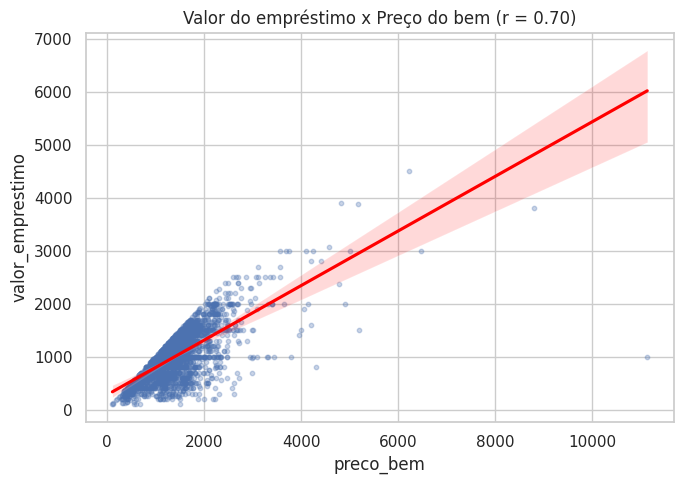

In [19]:
titulo("3a. REGRESSÃO LINEAR SIMPLES - pré-requisitos")

# Relação linear entre X e Y
r, p_r = st.pearsonr(treino["preco_bem"], treino["valor_emprestimo"])
rho, p_rho = st.spearmanr(treino["preco_bem"], treino["valor_emprestimo"])
print(f"Correlação de Pearson:  r = {r:.4f}  ({decisao(p_r, 'correlação = 0')})")
print(f"Correlação de Spearman: rho = {rho:.4f}")

plt.figure(figsize=(7, 5))
sns.regplot(data=treino, x="preco_bem", y="valor_emprestimo",
            scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
plt.title(f"Valor do empréstimo x Preço do bem (r = {r:.2f})")
salvar("01_rls_dispersao.png")




3a. REGRESSÃO LINEAR SIMPLES - modelo e adequação
                            OLS Regression Results                            
Dep. Variable:       valor_emprestimo   R-squared:                       0.484
Model:                            OLS   Adj. R-squared:                  0.483
Method:                 Least Squares   F-statistic:                     2646.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:14:20   Log-Likelihood:                -20397.
No. Observations:                2827   AIC:                         4.080e+04
Df Residuals:                    2825   BIC:                         4.081e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
I

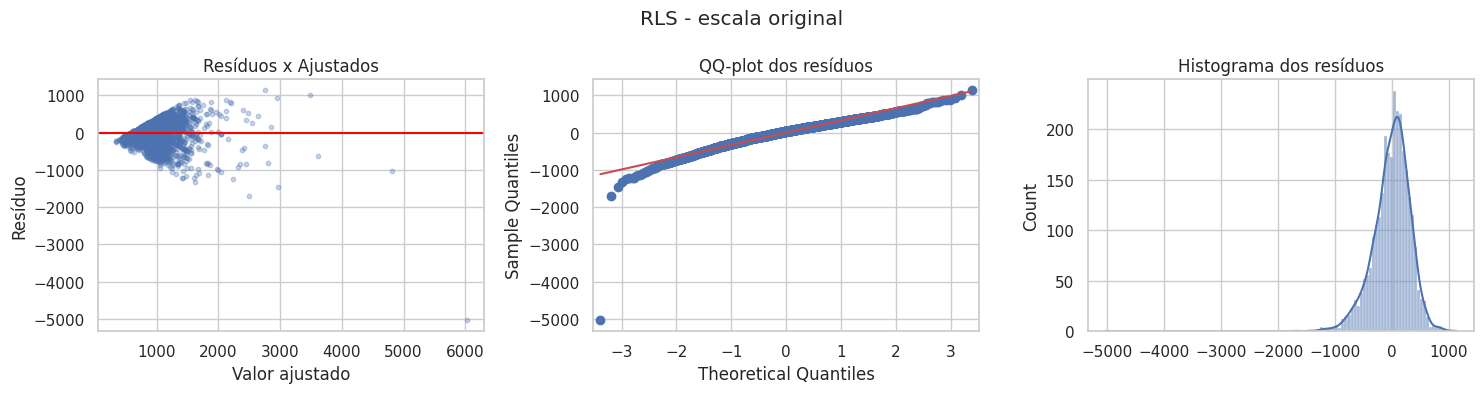

  [RLS original] Teste -> R² = 0.5297 | RMSE = 316.56 | MAE = 250.38


(0.5296995528150024, np.float64(316.5587742652092), 250.37859348678907)

In [20]:
titulo("3a. REGRESSÃO LINEAR SIMPLES - modelo e adequação")

# Criação do modelo (Mínimos Quadrados Ordinários)
rls = smf.ols("valor_emprestimo ~ preco_bem", data=treino).fit()
print(rls.summary())
b0, b1 = rls.params
print(f"\nEquação: valor_emprestimo = {b0:.2f} + {b1:.4f} * preco_bem")
print(f"Interpretação: a cada 1 unidade a mais no preço do bem, o empréstimo "
      f"solicitado aumenta em média {b1:.4f} unidade.")

# Análise da adequação
print(f"\nR² = {rls.rsquared:.4f} -> o preço do bem explica "
      f"{rls.rsquared:.1%} da variação do valor do empréstimo")
print(f"Teste F (significância do modelo): {decisao(rls.f_pvalue, 'modelo não significativo')}")
print(f"Teste t (b1): {decisao(rls.pvalues['preco_bem'], 'b1 = 0')}")
print("\nPressupostos dos resíduos (escala original):")
diagnostico_residuos(rls, "02_rls_residuos.png", "RLS - escala original")
metricas_teste(teste["valor_emprestimo"], rls.predict(teste), "RLS original")




3a. REGRESSÃO LINEAR SIMPLES - cenários
Cenário 2 - modelo log-log: ln(valor_emprestimo) = b0 + b1 * ln(preco_bem)
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.6790      0.116      5.840      0.000       0.451       0.907
np.log(preco_bem)     0.8539      0.016     52.947      0.000       0.822       0.885
R² (escala log) = 0.4981
Elasticidade: preço do bem 1% maior -> empréstimo 0.854% maior, em média
  Normalidade - Shapiro-Wilk:      W = 0.8325, p = 0.0000 < 0,05 -> rejeita H0 (resíduos normais)
  Normalidade - Kolmogorov-Smirnov: D = 0.1479, p = 0.0010 < 0,05 -> rejeita H0 (resíduos normais)
  Homocedasticidade - Breusch-Pagan: LM = 15.99, p = 0.0001 < 0,05 -> rejeita H0 (variância constante)
  Independência - Durbin-Watson: 1.970 -> ok (entre 1,5 e 2,5)


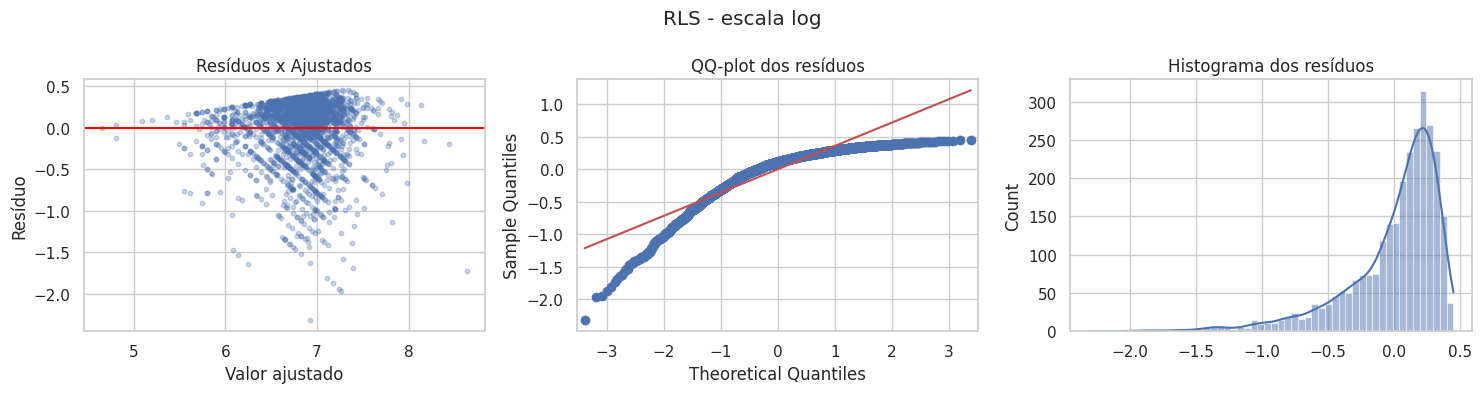

  [RLS log-log] Teste -> R² = 0.5273 | RMSE = 317.37 | MAE = 255.61

b1 com erro-padrão robusto (HC3): 0.5153 (EP = 0.0523, p = 0.0000)

Simulação - empréstimo previsto para diferentes preços de bem:
 preco_bem  previsto  IC95%_inf  IC95%_sup  previsto_loglog
       500     540.0     -106.0     1185.0            398.0
      1000     797.0      152.0     1443.0            719.0
      1500    1055.0      410.0     1701.0           1016.0
      2500    1570.0      925.0     2216.0           1572.0
      4000    2343.0     1696.0     2991.0           2348.0


In [21]:
titulo("3a. REGRESSÃO LINEAR SIMPLES - cenários")

# Cenário 2: transformação log-log para corrigir violações dos pressupostos
print("Cenário 2 - modelo log-log: ln(valor_emprestimo) = b0 + b1 * ln(preco_bem)")
rls_log = smf.ols("np.log(valor_emprestimo) ~ np.log(preco_bem)", data=treino).fit()
print(rls_log.summary().tables[1])
print(f"R² (escala log) = {rls_log.rsquared:.4f}")
print(f"Elasticidade: preço do bem 1% maior -> empréstimo "
      f"{rls_log.params.iloc[1]:.3f}% maior, em média")
diagnostico_residuos(rls_log, "03_rls_log_residuos.png", "RLS - escala log")
metricas_teste(teste["valor_emprestimo"], np.exp(rls_log.predict(teste)), "RLS log-log")

# Cenário 3: erros-padrão robustos (HC3) caso a heterocedasticidade persista
rls_rob = smf.ols("valor_emprestimo ~ preco_bem", data=treino).fit(cov_type="HC3")
print(f"\nb1 com erro-padrão robusto (HC3): {rls_rob.params['preco_bem']:.4f} "
      f"(EP = {rls_rob.bse['preco_bem']:.4f}, p = {rls_rob.pvalues['preco_bem']:.4f})")

# Simulação: empréstimo previsto para diferentes preços de bem
print("\nSimulação - empréstimo previsto para diferentes preços de bem:")
cen = pd.DataFrame({"preco_bem": [500, 1000, 1500, 2500, 4000]})
pred = rls.get_prediction(cen).summary_frame(alpha=0.05)
cen["previsto"] = pred["mean"].round(0)
cen["IC95%_inf"] = pred["obs_ci_lower"].round(0)
cen["IC95%_sup"] = pred["obs_ci_upper"].round(0)
cen["previsto_loglog"] = np.exp(rls_log.predict(cen)).round(0)
print(cen.to_string(index=False))

# Modelo: valor_emprestimo = b0 + b1*preco_bem + b2*prazo + b3*renda + ... + e



3b. REGRESSÃO LINEAR MÚLTIPLA - pré-requisitos
Correlação de cada variável com o valor do empréstimo:
preco_bem        0.695
prazo            0.467
renda            0.180
patrimonio       0.179
divida           0.073
despesas         0.036
idade           -0.005
tempo_emprego   -0.017
Name: valor_emprestimo, dtype: float64


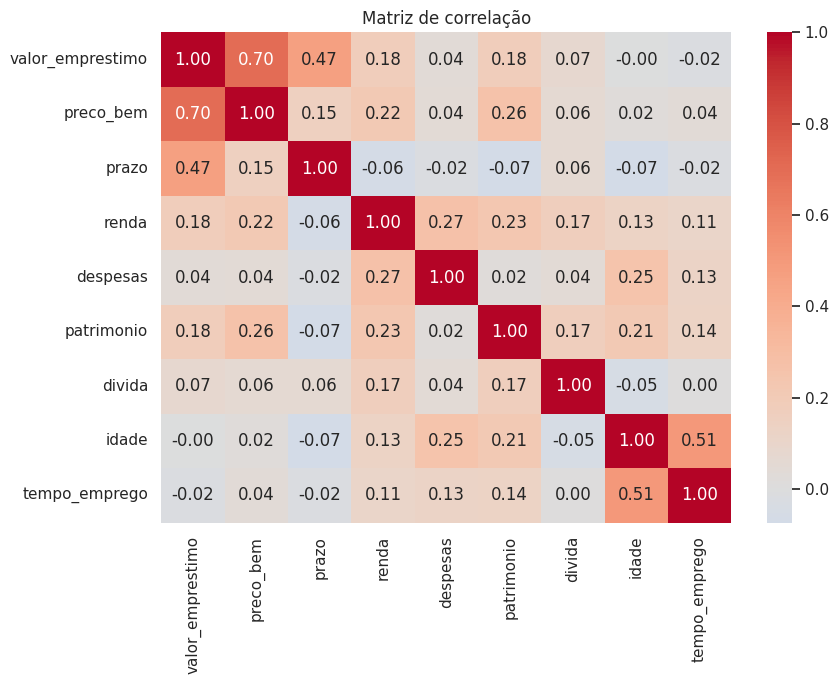


Multicolinearidade (VIF < 5 = aceitável; VIF > 10 = problema):
     variavel  VIF
    preco_bem 1.15
        prazo 1.05
        renda 1.21
     despesas 1.15
   patrimonio 1.20
       divida 1.07
        idade 1.48
tempo_emprego 1.35


In [22]:
titulo("3b. REGRESSÃO LINEAR MÚLTIPLA - pré-requisitos")

num_vars = ["preco_bem", "prazo", "renda", "despesas", "patrimonio",
            "divida", "idade", "tempo_emprego"]

# Correlação de cada X com Y
corr = treino[["valor_emprestimo"] + num_vars].corr()
print("Correlação de cada variável com o valor do empréstimo:")
print(corr["valor_emprestimo"].drop("valor_emprestimo").sort_values(ascending=False).round(3))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação")
salvar("04_rlm_correlacao.png")

# Multicolinearidade entre os X
print("\nMulticolinearidade (VIF < 5 = aceitável; VIF > 10 = problema):")
print(tabela_vif(treino, num_vars).to_string(index=False))




3b. REGRESSÃO LINEAR MÚLTIPLA - modelo e adequação
Modelo completo: R² = 0.6325 | R² ajustado = 0.6298 | AIC = 39877
  removendo 'despesas' (p = 0.9539)
  removendo 'divida' (p = 0.9275)
  removendo 'idade' (p = 0.2118)
  removendo 'C(estado_civil)' (p = 0.3052)
                            OLS Regression Results                            
Dep. Variable:       valor_emprestimo   R-squared:                       0.632
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     344.9
Date:                Thu, 29 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:14:34   Log-Likelihood:                -19918.
No. Observations:                2827   AIC:                         3.987e+04
Df Residuals:                    2812   BIC:                         3.996e+04
Df Model:                          14                                         
Covariance Type:         

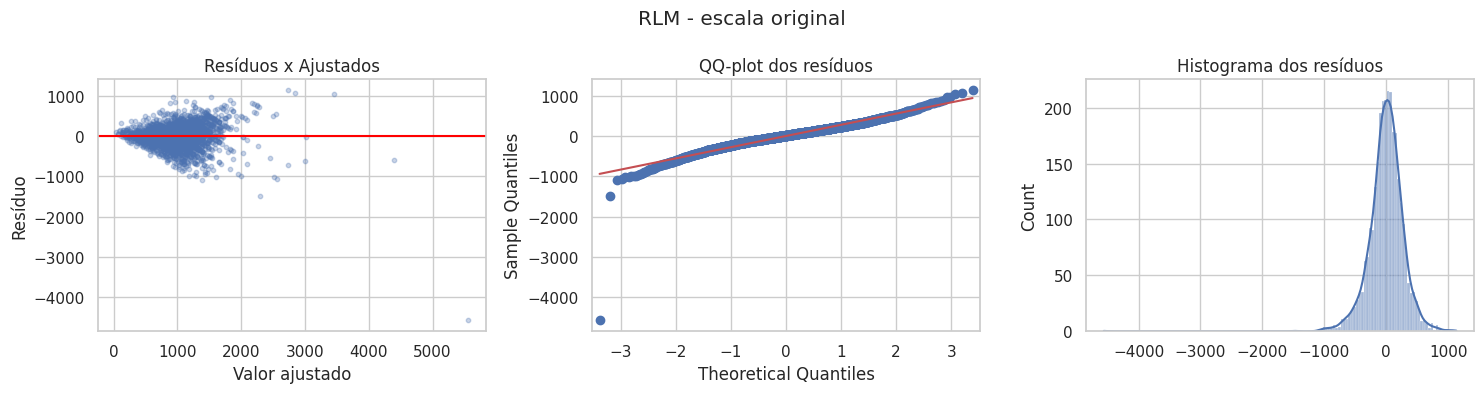

  [RLM original] Teste -> R² = 0.6511 | RMSE = 272.65 | MAE = 202.99


(0.6511102908935325, np.float64(272.6532881799364), 202.9906688831138)

In [23]:
titulo("3b. REGRESSÃO LINEAR MÚLTIPLA - modelo e adequação")

# Modelo completo (todas as variáveis)
formula_rlm = ("valor_emprestimo ~ preco_bem + prazo + renda + despesas + patrimonio"
               " + divida + idade + tempo_emprego + restricao + C(tipo_emprego)"
               " + C(moradia) + C(estado_civil)")
rlm_full = smf.ols(formula_rlm, data=treino).fit()
print(f"Modelo completo: R² = {rlm_full.rsquared:.4f} | "
      f"R² ajustado = {rlm_full.rsquared_adj:.4f} | AIC = {rlm_full.aic:.0f}")

# Seleção de variáveis: eliminação backward (remove o maior p-valor > 0,05)
termos = ["preco_bem", "prazo", "renda", "despesas", "patrimonio", "divida",
          "idade", "tempo_emprego", "restricao", "C(tipo_emprego)",
          "C(moradia)", "C(estado_civil)"]
while True:
    rlm = smf.ols("valor_emprestimo ~ " + " + ".join(termos), data=treino).fit()
    pvals = {t: p_termo(rlm, t) for t in termos}
    pior = max(pvals, key=pvals.get)
    if pvals[pior] <= ALPHA:
        break
    print(f"  removendo '{pior}' (p = {pvals[pior]:.4f})")
    termos.remove(pior)

print(rlm.summary())

# Análise da adequação
print(f"\nR² = {rlm.rsquared:.4f} | R² ajustado = {rlm.rsquared_adj:.4f} "
      f"(RLS tinha R² = {rls.rsquared:.4f})")
print(f"Teste F global: {decisao(rlm.f_pvalue, 'todos os coeficientes = 0')}")
num_final = [t for t in termos if t in num_vars]
print("\nVIF das variáveis numéricas do modelo final:")
print(tabela_vif(treino, num_final).to_string(index=False))
print("\nPressupostos dos resíduos (escala original):")
diagnostico_residuos(rlm, "05_rlm_residuos.png", "RLM - escala original")
metricas_teste(teste["valor_emprestimo"], rlm.predict(teste), "RLM original")




3b. REGRESSÃO LINEAR MÚLTIPLA - cenários
Cenário 2 - RLM com log: R² (escala log) = 0.6592 | R² ajustado = 0.6575
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                           1.0930      0.101     10.784      0.000       0.894       1.292
C(tipo_emprego)[T.fixo]            -0.0752      0.016     -4.841      0.000      -0.106      -0.045
C(tipo_emprego)[T.meio_periodo]    -0.0272      0.023     -1.190      0.234      -0.072       0.018
C(tipo_emprego)[T.outros]          -0.0193      0.032     -0.597      0.550      -0.083       0.044
C(moradia)[T.ignorado]              0.1092      0.086      1.263      0.207      -0.060       0.279
C(moradia)[T.outros]                0.0176      0.024      0.724      0.469      -0.030       0.065
C(moradia)[T.pais]                 -0.0362      0.018     -2.009      0.045      -0.0

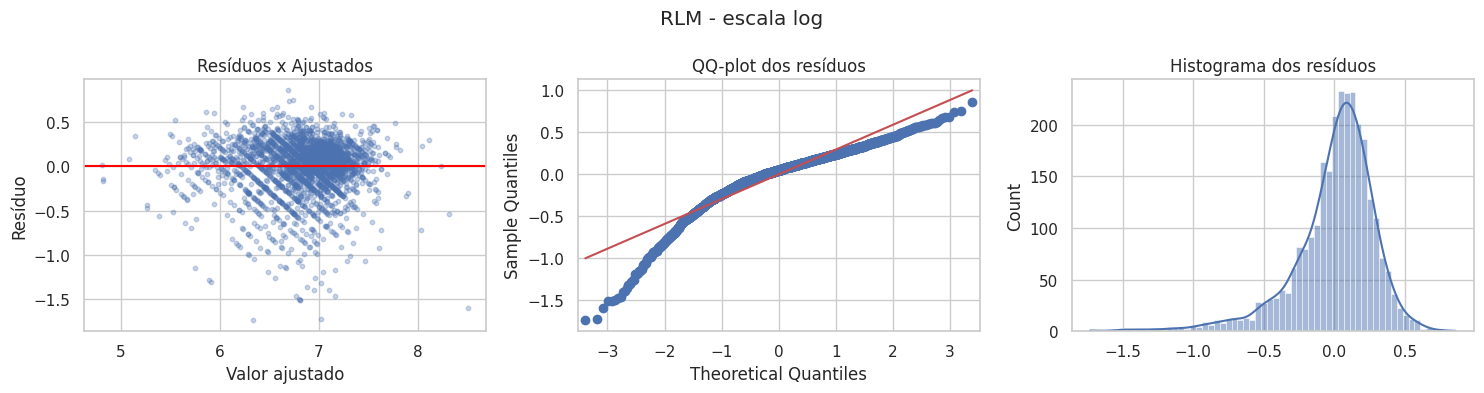

  [RLM log] Teste -> R² = 0.6234 | RMSE = 283.28 | MAE = 205.48

Simulação - bem de preço 1.500 com perfis diferentes de cliente:
                        perfil  prazo  renda  previsto  previsto_log
Prazo curto (24m), renda baixa     24     80     717.0         672.0
Prazo médio (48m), renda média     48    130    1028.0         967.0
 Prazo longo (60m), renda alta     60    250    1216.0        1199.0


In [24]:
titulo("3b. REGRESSÃO LINEAR MÚLTIPLA - cenários")

# Cenário 2: log do valor do empréstimo e do preço do bem
formula_log = "np.log(valor_emprestimo) ~ " + " + ".join(
    ["np.log(preco_bem)" if t == "preco_bem" else t for t in termos])
rlm_log = smf.ols(formula_log, data=treino).fit()
print(f"Cenário 2 - RLM com log: R² (escala log) = {rlm_log.rsquared:.4f} | "
      f"R² ajustado = {rlm_log.rsquared_adj:.4f}")
print(rlm_log.summary().tables[1])
diagnostico_residuos(rlm_log, "06_rlm_log_residuos.png", "RLM - escala log")
metricas_teste(teste["valor_emprestimo"], np.exp(rlm_log.predict(teste)), "RLM log")

# Simulação: mesmo bem, clientes com perfis diferentes
print("\nSimulação - bem de preço 1.500 com perfis diferentes de cliente:")
base = treino.mode().iloc[0]  # categorias mais comuns
perfis = pd.DataFrame([
    {"perfil": "Prazo curto (24m), renda baixa", "prazo": 24, "renda": 80},
    {"perfil": "Prazo médio (48m), renda média", "prazo": 48, "renda": 130},
    {"perfil": "Prazo longo (60m), renda alta", "prazo": 60, "renda": 250},
])
for col in ["despesas", "patrimonio", "divida", "idade", "tempo_emprego"]:
    perfis[col] = treino[col].median()
perfis["preco_bem"] = 1500
for col in ["restricao", "tipo_emprego", "moradia", "estado_civil"]:
    perfis[col] = base[col]
perfis["previsto"] = rlm.predict(perfis).round(0)
perfis["previsto_log"] = np.exp(rlm_log.predict(perfis)).round(0)
print(perfis[["perfil", "prazo", "renda", "previsto", "previsto_log"]].to_string(index=False))

# Modelo: P(inadimplente = 1) = 1 / (1 + e^-(b0 + b1*x1 + ... + bk*xk))



3c. REGRESSÃO LOGÍSTICA BINÁRIA - pré-requisitos
1) Variável resposta dicotômica:
inadimplente
bom pagador     2109
inadimplente     718
Name: count, dtype: int64

2) Tamanho amostral: 718 eventos / 22 parâmetros = 33 eventos por variável (mínimo recomendado: 10)

3) Ausência de multicolinearidade (VIF):
        variavel  VIF
   tempo_emprego 1.36
           prazo 1.49
           idade 1.48
        despesas 1.15
           renda 1.21
      patrimonio 1.19
          divida 1.07
valor_emprestimo 1.61
  pct_financiado 1.48

4) Diferença entre os grupos (Mann-Whitney) - variáveis com potencial preditivo:
   tempo_emprego     média bons =      9.30 | média inadimpl. =      4.50 | p = 0.0000
   prazo             média bons =     45.93 | média inadimpl. =     48.85 | p = 0.0001
   idade             média bons =     37.70 | média inadimpl. =     34.71 | p = 0.0000
   despesas          média bons =     55.54 | média inadimpl. =     57.50 | p = 0.1797
   renda             média bons =    149.20

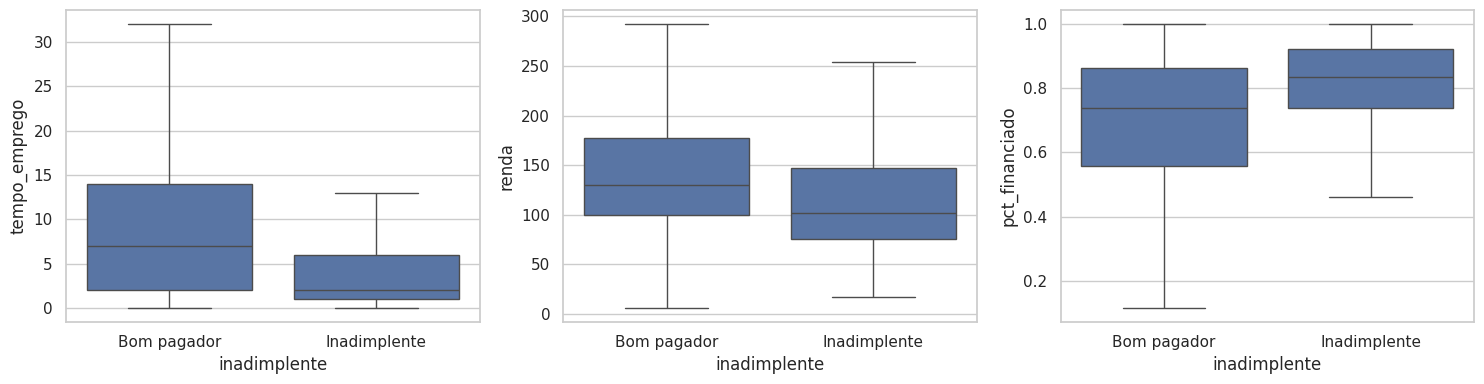


5) Independência das observações: cada linha é um cliente diferente -> ok


In [25]:
titulo("3c. REGRESSÃO LOGÍSTICA BINÁRIA - pré-requisitos")

# Variável de engenharia: quanto do bem está sendo financiado
for d in (treino, teste):
    d["pct_financiado"] = d["valor_emprestimo"] / d["preco_bem"]

print("1) Variável resposta dicotômica:")
print(treino["inadimplente"].value_counts().rename({0: "bom pagador", 1: "inadimplente"}))

termos_log = ["tempo_emprego", "C(moradia)", "prazo", "idade", "C(estado_civil)",
              "restricao", "C(tipo_emprego)", "despesas", "renda", "patrimonio",
              "divida", "valor_emprestimo", "pct_financiado"]
n_eventos = treino["inadimplente"].sum()
n_params = smf.logit("inadimplente ~ " + " + ".join(termos_log),
                     data=treino).fit(disp=0).df_model
print(f"\n2) Tamanho amostral: {n_eventos} eventos / {n_params:.0f} parâmetros = "
      f"{n_eventos / n_params:.0f} eventos por variável (mínimo recomendado: 10)")

num_log = ["tempo_emprego", "prazo", "idade", "despesas", "renda", "patrimonio",
           "divida", "valor_emprestimo", "pct_financiado"]
print("\n3) Ausência de multicolinearidade (VIF):")
print(tabela_vif(treino, num_log).to_string(index=False))

print("\n4) Diferença entre os grupos (Mann-Whitney) - variáveis com potencial preditivo:")
for v in num_log:
    _, p = st.mannwhitneyu(treino.loc[treino.inadimplente == 1, v],
                           treino.loc[treino.inadimplente == 0, v])
    print(f"   {v:<17} média bons = {treino.loc[treino.inadimplente == 0, v].mean():>9.2f} | "
          f"média inadimpl. = {treino.loc[treino.inadimplente == 1, v].mean():>9.2f} | p = {p:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, v in zip(ax, ["tempo_emprego", "renda", "pct_financiado"]):
    sns.boxplot(data=treino, x="inadimplente", y=v, ax=a, showfliers=False)
    a.set_xticklabels(["Bom pagador", "Inadimplente"])
salvar("07_log_boxplots.png")

print("\n5) Independência das observações: cada linha é um cliente diferente -> ok")



In [26]:
titulo("3c. REGRESSÃO LOGÍSTICA BINÁRIA - modelo")

# Seleção backward (remove o maior p-valor > 0,05)
termos_sel = termos_log.copy()
while True:
    logit = smf.logit("inadimplente ~ " + " + ".join(termos_sel), data=treino).fit(disp=0)
    pvals = {t: p_termo(logit, t) for t in termos_sel}
    pior = max(pvals, key=pvals.get)
    if pvals[pior] <= ALPHA:
        break
    print(f"  removendo '{pior}' (p = {pvals[pior]:.4f})")
    termos_sel.remove(pior)

print(logit.summary())

# Odds ratios: e^b -> quanto a chance de inadimplência é multiplicada
ic = np.exp(logit.conf_int())
odds = pd.DataFrame({"odds_ratio": np.exp(logit.params), "IC95%_inf": ic[0],
                     "IC95%_sup": ic[1], "p_valor": logit.pvalues}).round(4)
print("\nOdds ratios (OR > 1 aumenta o risco; OR < 1 reduz o risco):")
print(odds.drop("Intercept").to_string())




3c. REGRESSÃO LOGÍSTICA BINÁRIA - modelo
  removendo 'idade' (p = 0.3481)
  removendo 'prazo' (p = 0.0632)
                           Logit Regression Results                           
Dep. Variable:           inadimplente   No. Observations:                 2827
Model:                          Logit   Df Residuals:                     2806
Method:                           MLE   Df Model:                           20
Date:                Thu, 29 Oct 2026   Pseudo R-squ.:                  0.2691
Time:                        21:14:39   Log-Likelihood:                -1170.8
converged:                       True   LL-Null:                       -1602.0
Covariance Type:            nonrobust   LLR p-value:                8.496e-170
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
Intercept                          -3.6034      0.402     -8

In [27]:
titulo("3c. REGRESSÃO LOGÍSTICA BINÁRIA - adequação")

print(f"Pseudo-R² de McFadden = {logit.prsquared:.4f}")
print(f"Teste da razão de verossimilhança (LR) = {logit.llr:.2f}, "
      + decisao(logit.llr_pvalue, "modelo igual ao modelo só com intercepto"))
print(f"AIC = {logit.aic:.0f}")

hl, hl_p = hosmer_lemeshow(treino["inadimplente"], logit.predict(treino))
print(f"Hosmer-Lemeshow: X² = {hl:.2f}, " + decisao(hl_p, "modelo bem ajustado"))

# Desempenho na base de teste
prob = logit.predict(teste)
y_teste = teste["inadimplente"]
auc = roc_auc_score(y_teste, prob)
fpr, tpr, cortes = roc_curve(y_teste, prob)
ks = np.max(tpr - fpr)
print(f"\nAUC (teste) = {auc:.4f} | KS (teste) = {ks:.4f}  "
      f"(KS é a métrica mais usada em modelos de crédito)")

print("\nMatriz de confusão (corte 0,5) - linhas = real, colunas = previsto:")
print(pd.DataFrame(confusion_matrix(y_teste, (prob >= 0.5).astype(int)),
                   index=["real bom", "real inadimpl."],
                   columns=["prev. bom", "prev. inadimpl."]))




3c. REGRESSÃO LOGÍSTICA BINÁRIA - adequação
Pseudo-R² de McFadden = 0.2691
Teste da razão de verossimilhança (LR) = 862.23, p = 0.0000 < 0,05 -> rejeita H0 (modelo igual ao modelo só com intercepto)
AIC = 2384
Hosmer-Lemeshow: X² = 8.95, p = 0.3467 >= 0,05 -> não rejeita H0 (modelo bem ajustado)

AUC (teste) = 0.8374 | KS (teste) = 0.5411  (KS é a métrica mais usada em modelos de crédito)

Matriz de confusão (corte 0,5) - linhas = real, colunas = previsto:
                prev. bom  prev. inadimpl.
real bom              845               59
real inadimpl.        170              138



3c. REGRESSÃO LOGÍSTICA BINÁRIA - cenários
Simulação - diferentes pontos de corte (política de crédito):
 corte  acuracia  sensibilidade  especificidade  precisao    f1
   0.2     0.729          0.834           0.694     0.481 0.610
   0.3     0.790          0.695           0.823     0.572 0.628
   0.4     0.809          0.584           0.885     0.634 0.608
   0.5     0.811          0.448           0.935     0.701 0.547
   0.6     0.801          0.341           0.958     0.734 0.466
Corte ótimo (índice de Youden): 0.271


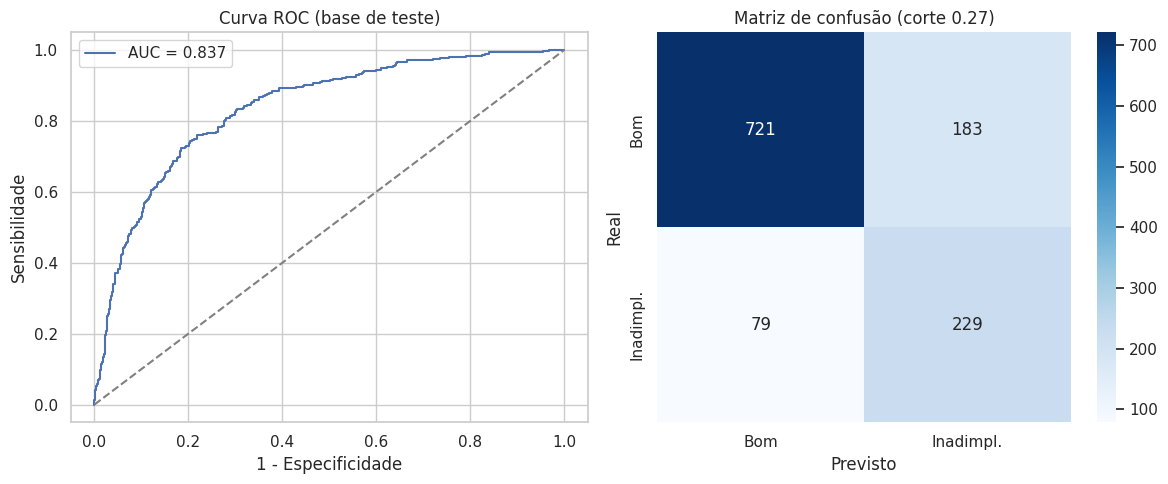


Simulação - probabilidade de inadimplência para clientes hipotéticos:
                                               perfil prob_inadimplencia
Estável: 10 anos emprego, casa própria, sem restrição               5.4%
Intermediário: 3 anos emprego, aluguel, sem restrição              20.6%
    Arriscado: 0 anos emprego, aluguel, com restrição              92.4%


In [28]:
titulo("3c. REGRESSÃO LOGÍSTICA BINÁRIA - cenários")


def avaliar_corte(c):
    prev = (prob >= c).astype(int)
    return {"corte": c, "acuracia": accuracy_score(y_teste, prev),
            "sensibilidade": recall_score(y_teste, prev),
            "especificidade": recall_score(y_teste, prev, pos_label=0),
            "precisao": precision_score(y_teste, prev),
            "f1": f1_score(y_teste, prev)}


# Cenário 1: política de crédito mais ou menos conservadora
print("Simulação - diferentes pontos de corte (política de crédito):")
print(pd.DataFrame([avaliar_corte(c) for c in [0.2, 0.3, 0.4, 0.5, 0.6]])
      .round(3).to_string(index=False))
corte_youden = cortes[np.argmax(tpr - fpr)]
print(f"Corte ótimo (índice de Youden): {corte_youden:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(title="Curva ROC (base de teste)", xlabel="1 - Especificidade",
          ylabel="Sensibilidade")
ax[0].legend()
sns.heatmap(confusion_matrix(y_teste, (prob >= corte_youden).astype(int)), annot=True,
            fmt="d", cmap="Blues", ax=ax[1],
            xticklabels=["Bom", "Inadimpl."], yticklabels=["Bom", "Inadimpl."])
ax[1].set(title=f"Matriz de confusão (corte {corte_youden:.2f})",
          xlabel="Previsto", ylabel="Real")
salvar("08_log_roc_confusao.png")

# Cenário 2: clientes hipotéticos
print("\nSimulação - probabilidade de inadimplência para clientes hipotéticos:")
clientes = pd.DataFrame([
    {"perfil": "Estável: 10 anos emprego, casa própria, sem restrição",
     "tempo_emprego": 10, "moradia": "propria", "restricao": 0, "tipo_emprego": "fixo",
     "renda": 180},
    {"perfil": "Intermediário: 3 anos emprego, aluguel, sem restrição",
     "tempo_emprego": 3, "moradia": "aluguel", "restricao": 0, "tipo_emprego": "fixo",
     "renda": 120},
    {"perfil": "Arriscado: 0 anos emprego, aluguel, com restrição",
     "tempo_emprego": 0, "moradia": "aluguel", "restricao": 1, "tipo_emprego": "meio_periodo",
     "renda": 80},
])
for col in ["prazo", "idade", "despesas", "patrimonio", "divida", "valor_emprestimo"]:
    clientes[col] = treino[col].median()
clientes["pct_financiado"] = treino["pct_financiado"].median()
clientes["estado_civil"] = "casado"
clientes["prob_inadimplencia"] = logit.predict(clientes).map("{:.1%}".format)
print(clientes[["perfil", "prob_inadimplencia"]].to_string(index=False))

